
## Como as aplicações se distribuem entre os bairros?
### PyAnalitcs-Sprint 3

In [51]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


In [52]:
df = pd.read_csv('vacinas_analitico.csv')
df.head()

,nome_do_bairro,nome_da_vacina,codigo_da_vacina,estrategia,codigo_da_estrategia,dose,codigo_da_dose,vacina_estrategia_e_dose,lote,validade_do_lote,data_da_aplicacao,origem
0,Arapongas,"Vacina COVID-19-RNAm, Pfizer (Comirnaty)",87,Rotina,1,REVACINAÇÃO,10.0,"Vacina COVID-19-RNAm, Pfizer (Comirnaty) (87) ...",MT7306,17/04/2026,02/04/2026,Tela de Aplicação
1,Arapongas,"Vacina COVID-19-RNAm, Pfizer (Comirnaty)",87,Rotina,1,REVACINAÇÃO,10.0,"Vacina COVID-19-RNAm, Pfizer (Comirnaty) (87) ...",MT7306,17/04/2026,02/04/2026,Tela de Aplicação
2,Arapongas,"Vacina COVID-19-RNAm, Pfizer (Comirnaty)",87,Rotina,1,REVACINAÇÃO,10.0,"Vacina COVID-19-RNAm, Pfizer (Comirnaty) (87) ...",MT7306,17/04/2026,02/04/2026,Tela de Aplicação
3,Arapongas,"Vacina COVID-19-RNAm, Pfizer (Comirnaty)",87,Rotina,1,REVACINAÇÃO,10.0,"Vacina COVID-19-RNAm, Pfizer (Comirnaty) (87) ...",MT7306,17/04/2026,02/04/2026,Tela de Aplicação
4,Arapongas,"Vacina COVID-19-RNAm, Pfizer (Comirnaty)",87,Rotina,1,REVACINAÇÃO,10.0,"Vacina COVID-19-RNAm, Pfizer (Comirnaty) (87) ...",MT7306,17/04/2026,02/04/2026,Tela de Aplicação


## 1. Preparação dos Dados

In [53]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 30883 entries, 0 to 30882
Data columns (total 12 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   nome_do_bairro            30883 non-null  str    
 1   nome_da_vacina            30883 non-null  str    
 2   codigo_da_vacina          30883 non-null  int64  
 3   estrategia                30883 non-null  str    
 4   codigo_da_estrategia      30883 non-null  int64  
 5   dose                      30874 non-null  str    
 6   codigo_da_dose            30874 non-null  float64
 7   vacina_estrategia_e_dose  30883 non-null  str    
 8   lote                      30883 non-null  str    
 9   validade_do_lote          30883 non-null  str    
 10  data_da_aplicacao         30023 non-null  str    
 11  origem                    30023 non-null  str    
dtypes: float64(1), int64(2), str(9)
memory usage: 7.3 MB


A base possui 30.883 registros com 100% de preenchimento para bairros e vacinas. Apenas 860 linhas (2,8%) não têm data nem origem, tendo sido mantidas para não subestimar o total de doses aplicadas por território.

In [54]:
df.columns.tolist()

['nome_do_bairro',
 'nome_da_vacina',
 'codigo_da_vacina',
 'estrategia',
 'codigo_da_estrategia',
 'dose',
 'codigo_da_dose',
 'vacina_estrategia_e_dose',
 'lote',
 'validade_do_lote',
 'data_da_aplicacao',
 'origem']

In [55]:
df.isnull().sum()

nome_do_bairro                0
nome_da_vacina                0
codigo_da_vacina              0
estrategia                    0
codigo_da_estrategia          0
dose                          9
codigo_da_dose                9
vacina_estrategia_e_dose      0
lote                          0
validade_do_lote              0
data_da_aplicacao           860
origem                      860
dtype: int64

In [56]:
df['dose'] = df['dose'].fillna('NÃO INFORMADO')
df['codigo_da_dose'] = df['codigo_da_dose'].fillna(-1)
df['origem'] = df['origem'].fillna('NÃO INFORMADO')

df.isnull().sum()

nome_do_bairro                0
nome_da_vacina                0
codigo_da_vacina              0
estrategia                    0
codigo_da_estrategia          0
dose                          0
codigo_da_dose                0
vacina_estrategia_e_dose      0
lote                          0
validade_do_lote              0
data_da_aplicacao           860
origem                        0
dtype: int64

Os campos dose e origem foram preenchidos com 'NÃO INFORMADO' para eliminar valores nulos em variáveis categóricas. A coluna data_da_aplicacao manteve os seus 860 nulos em aberto para permitir a conversão temporal sem corromper as contagens por bairro.

## 2. Quais bairros apresentam maior ou menor movimento?

In [57]:
contagem_bairros = df['nome_do_bairro'].value_counts()

# Top 10  os bairros com maior fluxo
print("Bairros com Maior Fluxo")
print(contagem_bairros.head(10))


Bairros com Maior Fluxo
nome_do_bairro
Mato Alto Lagoão       4735
Bom Pastor             4064
Polícia Rodoviária     3290
Coloninha              3012
Jardim Cibele          2317
Vila São José          2131
Cidade Alta            1973
Divineia               1874
Jardim das Avenidas    1788
Arapongas              1414
Name: count, dtype: int64


Os bairros Mato Alto Lagoão (4.735) e Bom Pastor (4.064) lideram com folga o volume de vacinação no município. Este padrão aponta para uma forte centralização dos atendimentos nestes locais ou para a presença de salas de referência de grande porte, e não necessariamente para uma maior população residente.

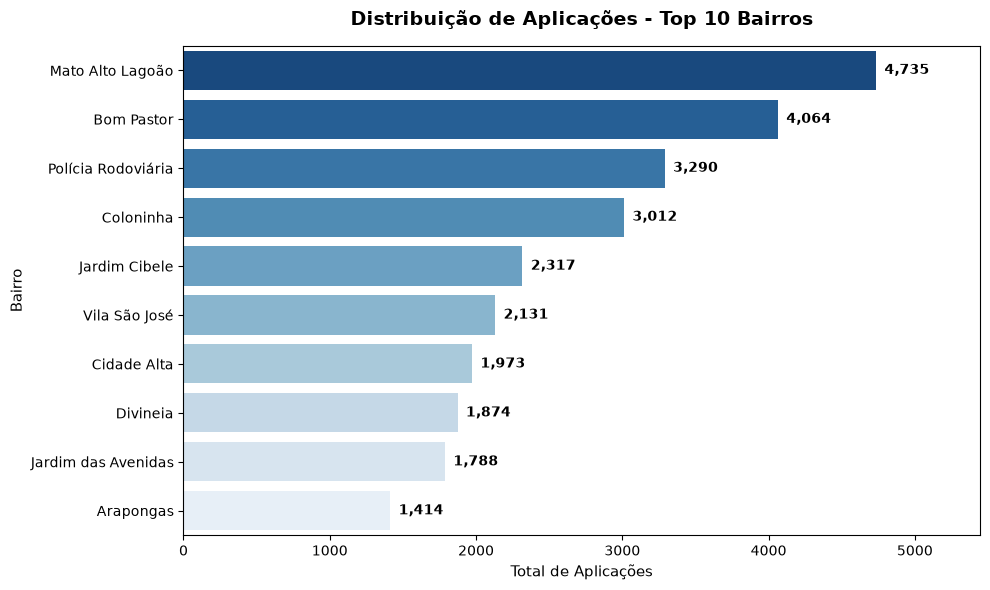

In [58]:


# Selecionar os 10 maiores
top10 = df['nome_do_bairro'].value_counts().head(10).reset_index()
top10.columns = ['Bairro', 'Aplicações']

plt.figure(figsize=(10, 6))
ax = sns.barplot(
    data=top10,
    x='Aplicações',
    y='Bairro',
    palette='Blues_r',
    hue='Bairro',
    legend=False
)

# Adicionar os valores numéricos no final de cada barra
for p in ax.patches:
    largura = p.get_width()
    ax.annotate(f'{int(largura):,}', 
                (largura, p.get_y() + p.get_height() / 2.),
                ha='left', va='center',
                xytext=(6, 0), textcoords='offset points',
                fontsize=10, color='black', weight='bold')

plt.title('Distribuição de Aplicações - Top 10 Bairros', fontsize=14, weight='bold', pad=15)
plt.xlabel('Total de Aplicações', fontsize=11)
plt.ylabel('Bairro', fontsize=11)
plt.xlim(0, top10['Aplicações'].max() * 1.15) 

plt.tight_layout()
plt.show()

A distribuição revela uma forte concentração de atendimentos em Mato Alto Lagoão (4.735) e Bom Pastor (4.064), evidenciando que estas unidades funcionam como os principais polos operacionais de imunização do município, o que reflete a capacidade instalada de atendimento desses postos e não necessariamente a dimensão populacional ou a cobertura vacinal dos residentes locais.

In [59]:
# Top 10 os bairros com menor fluxo 
print("\nBairros com Menor Fluxo")
print(contagem_bairros.tail(10))


Bairros com Menor Fluxo
nome_do_bairro
Vila São José          2131
Cidade Alta            1973
Divineia               1874
Jardim das Avenidas    1788
Arapongas              1414
Sanga da Areia         1405
Sanga da Toca           936
Urussanguinha           832
Hercilio Luz            690
Morro dos Conventos     422
Name: count, dtype: int64


A cauda inferior apresenta volumes substancialmente reduzidos, destacando-se Morro dos Conventos (422) e Hercílio Luz (698) com as menores contagens da lista, o que aponta para áreas periféricas ou balneares sem postos fixos de grande porte, levando a população a deslocar-se aos polos centrais, reforçando que um baixo volume de aplicações não equivale a uma baixa cobertura vacinal dos seus residentes.

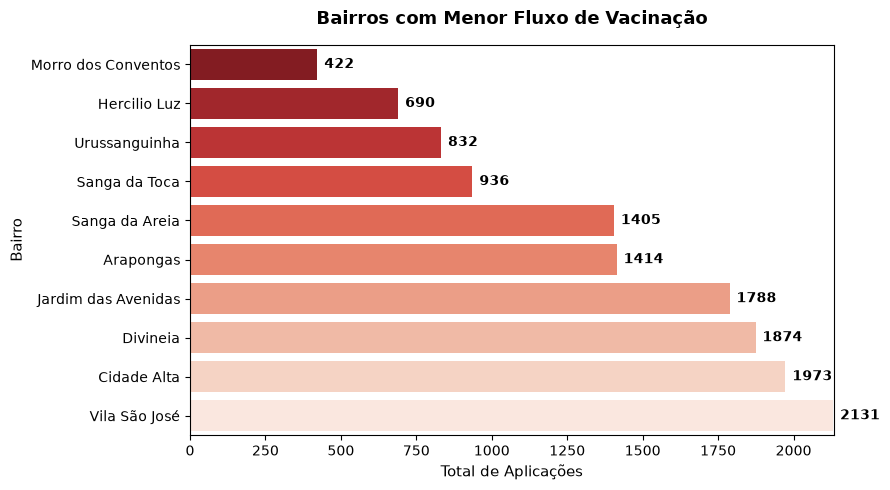

In [60]:
bottom10 = df['nome_do_bairro'].value_counts().tail(10).reset_index()
bottom10.columns = ['Bairro', 'Aplicações']
bottom10 = bottom10.sort_values(by='Aplicações', ascending=True)

plt.figure(figsize=(9, 5))
ax = sns.barplot(
    data=bottom10,
    x='Aplicações',
    y='Bairro',
    palette='Reds_r',
    hue='Bairro',
    legend=False
)

for p in ax.patches:
    largura = p.get_width()
    ax.annotate(f'{int(largura)}', 
                (largura, p.get_y() + p.get_height() / 2.),
                ha='left', va='center',
                xytext=(5, 0), textcoords='offset points',
                fontsize=10, weight='bold')

plt.title('Bairros com Menor Fluxo de Vacinação', fontsize=13, weight='bold', pad=15)
plt.xlabel('Total de Aplicações', fontsize=11)
plt.ylabel('Bairro', fontsize=11)
plt.xlim(0, max(bottom10['Aplicações'].max() + 2, 5))  # Espaço para o texto do número

plt.tight_layout()
plt.show()

A análise visual confirma o menor fluxo em localidades mais afastadas ou balneares, como Morro dos Conventos (422), Hercílio Luz (690) e Urussanguinha (832), evidenciando a ausência ou o funcionamento reduzido de postos fixos de grande porte nestes territórios, o que direciona a procura dos residentes para as unidades centrais e não indica, de forma alguma, baixa adesão ou menor cobertura vacinal da sua população.

## 3. Existem diferenças relevantes no perfil de vacinas entre os locais?

In [61]:
top_bairros = df['nome_do_bairro'].value_counts().head(10).index
top_vacinas = df['nome_da_vacina'].value_counts().head(10).index

df_perfil = df[df['nome_do_bairro'].isin(top_bairros) & df['nome_da_vacina'].isin(top_vacinas)]

In [62]:
perfil_percentual = (
    pd.crosstab(df_perfil['nome_do_bairro'], df_perfil['nome_da_vacina'], normalize='index') * 100
).round(1)

print("=== Composição Percentual de Vacinas por Bairro (%) ===")
display(perfil_percentual)

=== Composição Percentual de Vacinas por Bairro (%) ===


nome_da_vacina,Vacina dengue (atenuada),Vacina difteria e tétano adulto,Vacina febre amarela,Vacina hepatite B,Vacina influenza trivalente,Vacina meningo ACWY,Vacina penta (DTP/HepB/Hib),Vacina pneumo 10,Vacina polio injetável (inativada poliomielite),"Vacina sarampo, caxumba, rubéola"
nome_do_bairro,,,,,,,,,,
Arapongas,7.1,7.5,3.4,4.7,57.5,3.3,3.3,3.5,5.6,4.1
Bom Pastor,0.8,5.2,3.6,12.8,62.1,4.1,2.6,2.2,3.6,2.9
Cidade Alta,3.1,7.5,2.9,4.9,69.0,1.7,2.3,2.1,3.1,3.3
Coloninha,4.0,6.8,4.6,4.7,59.4,3.0,4.1,3.5,5.5,4.5
Divineia,2.8,3.8,2.6,2.7,72.5,2.2,3.0,2.6,4.7,3.1
Jardim Cibele,6.1,7.4,4.3,5.3,53.3,3.3,3.9,4.2,6.4,5.8
Jardim das Avenidas,3.2,7.2,4.4,5.4,65.9,2.0,2.4,2.8,3.6,3.1
Mato Alto Lagoão,9.6,7.7,4.8,3.9,52.7,3.2,4.2,4.1,5.6,4.2
Polícia Rodoviária,7.7,4.9,3.8,3.0,60.8,2.5,3.8,3.7,5.2,4.7


A Vacina influenza trivalente é amplamente dominante em todos os bairros analisados, representando entre 52,7% e 72,5% das doses aplicadas e evidenciando o forte peso de campanhas sazonais de vacinação no período registado. Observam-se ainda variações operacionais pontuais relevantes entre os locais, como o bairro Bom Pastor a destacar-se na aplicação de Hepatite B (12,8%, contra menos de 5% na maioria) e o Mato Alto Lagoão a liderar proporcionalmente a vacina da Dengue com 9,6%.

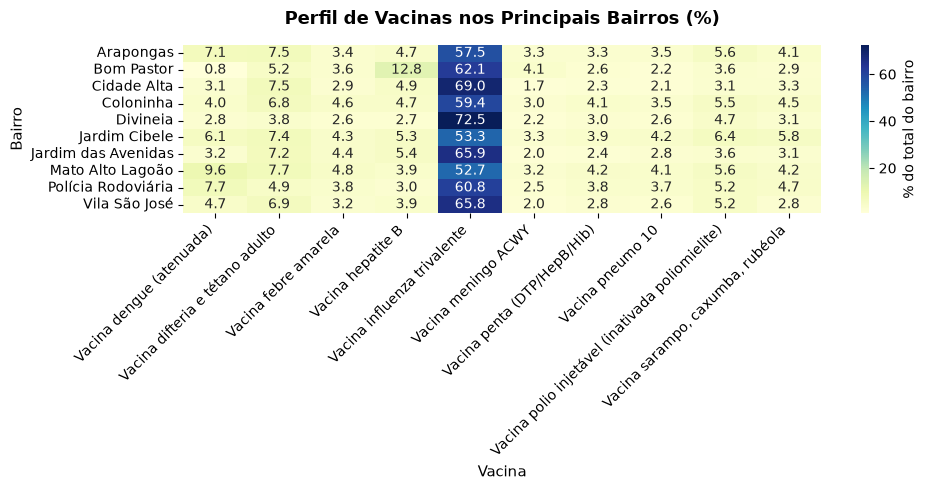

In [63]:
plt.figure(figsize=(10, 5))
sns.heatmap(perfil_percentual, annot=True, fmt='.1f', cmap='YlGnBu', cbar_kws={'label': '% do total do bairro'})
plt.title('Perfil de Vacinas nos Principais Bairros (%)', fontsize=13, weight='bold', pad=15)
plt.xlabel('Vacina', fontsize=11)
plt.ylabel('Bairro', fontsize=11)
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

O mapa de calor evidencia visualmente a hegemonia da Vacina influenza trivalente através do bloco azul intenso contínuo em todas as linhas (com picos de 72,5% na Divineia e 69,0% na Cidade Alta), ao passo que os imunizantes de rotina (como penta, pneumo e meningo) apresentam taxas uniformemente residuais (abaixo de 5%) — confirmando que o volume total de atendimentos do período foi fortemente impulsionado pela campanha sazonal contra a gripe, com desvios pontuais apenas na vacina contra a dengue no Mato Alto Lagoão (9,6%) e hepatite B no Bom Pastor (12,8%).

## 4. Quais locais apresentam comportamento diferente do conjunto da base?

In [64]:
volume_bairros = df['nome_do_bairro'].value_counts()

q1 = volume_bairros.quantile(0.25)
q3 = volume_bairros.quantile(0.75)
iqr = q3 - q1
limite_superior = q3 + 1.5 * iqr

outliers_volume_alto = volume_bairros[volume_bairros > limite_superior]
print(f"Bairros com volume atipicamente alto (acima de {limite_superior:.0f} doses):")
print(outliers_volume_alto)

Bairros com volume atipicamente alto (acima de 4906 doses):
Series([], Name: count, dtype: int64)


O teste estatístico de amplitude interquartil (IQR) estabeleceu o limite de corte em 4.906 doses e não detetou outliers na base (Series([])), confirmando que, apesar do grande volume nos bairros Mato Alto Lagoão e Bom Pastor, as aplicações diminuem de forma gradual e contínua por todo o município.

In [65]:
total_geral = len(df)
print("--- Proporção de vacinas na base inteira (%) ---")
geral = (df['nome_da_vacina'].value_counts() / total_geral * 100).round(1)
print(geral.head(3))


nome_bairro = 'Centro'  # bairro a ser comparado

dados_bairro = df[df['nome_do_bairro'] == nome_bairro]
total_bairro = len(dados_bairro)

print(f"\n--- Proporção de vacinas no bairro {nome_bairro} (%) ---")
bairro = (dados_bairro['nome_da_vacina'].value_counts() / total_bairro * 100).round(1)
print(bairro.head(3))

vacina_teste = geral.index[0]
diferenca = bairro.get(vacina_teste, 0) - geral[vacina_teste]

print(f"\nDiferença para a vacina '{vacina_teste}':")
print(f"Bairro {nome_bairro}: {bairro.get(vacina_teste, 0):.1f}%")
print(f"Média Geral: {geral[vacina_teste]:.1f}%")
print(f"Diferença simples: {diferenca:.1f}%")

--- Proporção de vacinas na base inteira (%) ---
nome_da_vacina
Vacina influenza trivalente        51.2
Vacina difteria e tétano adulto     5.2
Vacina hepatite B                   4.1
Name: count, dtype: float64

--- Proporção de vacinas no bairro Centro (%) ---
Series([], Name: count, dtype: float64)

Diferença para a vacina 'Vacina influenza trivalente':
Bairro Centro: 0.0%
Média Geral: 51.2%
Diferença simples: -51.2%


A Influenza lidera a base global com 51,2%, mas a pesquisa por 'Centro' retornou vazia (Series([])), confirmando a ausência desse nome cadastral no município e a necessidade de consultar bairros existentes como Mato Alto Lagoão.

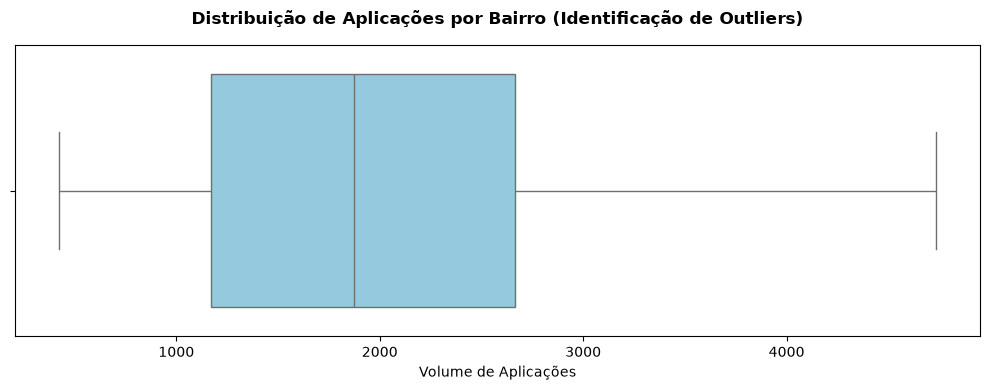

In [66]:
plt.figure(figsize=(10, 4))
sns.boxplot(x=volume_bairros, color='skyblue', flierprops={'markerfacecolor':'red', 'markersize':8})
plt.title('Distribuição de Aplicações por Bairro (Identificação de Outliers)', fontsize=12, weight='bold', pad=15)
plt.xlabel('Volume de Aplicações', fontsize=10)
plt.tight_layout()
plt.show()

O boxplot confirma que o volume de aplicações se distribui de forma contínua entre os bairros, com metade das localidades a registar entre ~1.150 e ~2.650 doses e uma mediana em torno de 1.870. A inexistência de pontos para além dos bigodes comprova que, pelo critério estatístico do IQR, não há bairros configurados como outliers isolados, existindo antes uma transição progressiva de movimento entre as unidades de saúde.

## 5. Quanto a ausência ou a mistura de código da sala e da UPS interfere na análise?

In [67]:
print("=== Valores mais frequentes em 'origem' ===")
display(df['origem'].value_counts(dropna=False).head(10))

=== Valores mais frequentes em 'origem' ===


origem
Carteirinha          24560
Prontuário            4722
NÃO INFORMADO          860
Tela de Aplicação      741
Name: count, dtype: int64

A coluna origem não discrimina códigos de postos, salas ou unidades produtoras de serviço (UPS/CNES), referindo-se antes à via de registo no sistema informático: Carteirinha lidera com 24.560 lançamentos, seguida por Prontuário (4.722), NÃO INFORMADO (860) e Tela de Aplicação (741). Isto revela uma limitação nos dados brutos, uma vez que a identificação da sala física de vacinação não se encontra codificada neste atributo.

In [68]:
total_registros = len(df)
ausentes_origem = (df['origem'].isna() | df['origem'].isin(['NÃO INFORMADO', 'SEM INFORMAÇÃO', 'NAN', ''])).sum()
pct_ausente = (ausentes_origem / total_registros) * 100

print(f"Total sem identificação de serviço: {ausentes_origem} ({pct_ausente:.2f}%)")

Total sem identificação de serviço: 860 (2.78%)


Registam-se exatamente 860 registos sem identificação de serviço (2,78%), correspondendo integralmente às linhas que antes estavam nulas e foram padronizadas como 'NÃO INFORMADO'. O impacto analítico destas ausências é reduzido, dado que a quase totalidade dos atendimentos (>97%) possui o canal de proveniência preenchido e mantém a consistência territorial preservada no campo de bairro.

In [69]:
unidade_bairro_cruzamento = df.groupby('origem')['nome_do_bairro'].nunique()
mistura_territorial = unidade_bairro_cruzamento[unidade_bairro_cruzamento > 1]

print(f"Unidades associadas a mais de um bairro (possível inconsistência cadastral): {len(mistura_territorial)}")
if len(mistura_territorial) > 0:
    display(mistura_territorial.head(10))

Unidades associadas a mais de um bairro (possível inconsistência cadastral): 4


origem
Carteirinha          15
NÃO INFORMADO         2
Prontuário           13
Tela de Aplicação     7
Name: nome_do_bairro, dtype: int64

O cruzamento confirma que todos os 4 valores de origem aparecem distribuídos por múltiplos territórios (por exemplo, Carteirinha presente em 15 bairros e Prontuário em 13). Isso comprova definitivamente que a coluna não representa postos físicos nem salas de vacinação, mas sim a modalidade de entrada no sistema, o que impede auditar fluxos específicos por sala ou UPS e restringe a análise territorial estritamente ao nível do endereço do bairro.

C:\Users\Manuel Etiene\AppData\Local\Temp\ipykernel_18976\1568242341.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(


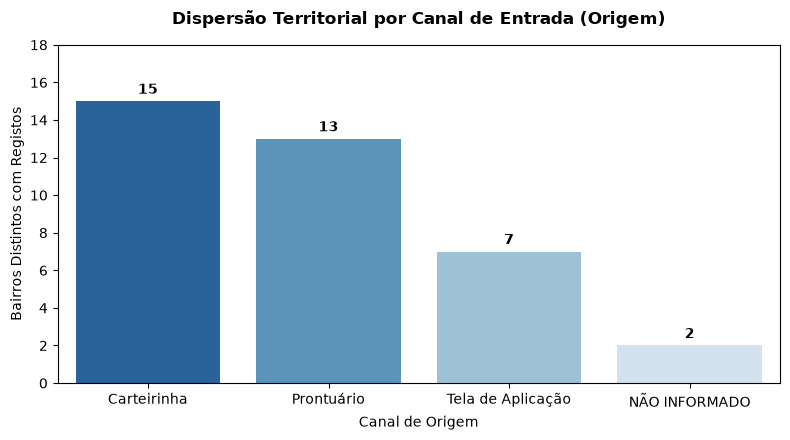

In [70]:
dados_grafico = df.groupby('origem')['nome_do_bairro'].nunique().reset_index()
dados_grafico.columns = ['Origem', 'Quantidade de Bairros']
dados_grafico = dados_grafico.sort_values(by='Quantidade de Bairros', ascending=False)

plt.figure(figsize=(8, 4.5))
ax = sns.barplot(
    data=dados_grafico,
    x='Origem',
    y='Quantidade de Bairros',
    palette='Blues_r'
)

for p in ax.patches:
    altura = p.get_height()
    ax.annotate(
        f'{int(altura)}',
        (p.get_x() + p.get_width() / 2., altura),
        ha='center', va='bottom',
        fontsize=10, weight='bold',
        xytext=(0, 3), textcoords='offset points'
    )

plt.title('Dispersão Territorial por Canal de Entrada (Origem)', fontsize=12, weight='bold', pad=15)
plt.xlabel('Canal de Origem', fontsize=10)
plt.ylabel('Bairros Distintos com Registos', fontsize=10)
plt.ylim(0, max(dados_grafico['Quantidade de Bairros']) + 3)
plt.tight_layout()
plt.show()

O gráfico demonstra a ampla transversalidade dos canais de registo, com Carteirinha presente em 15 bairros e Prontuário em 13. Esta abrangência comprova visualmente a inexistência de uma relação unívoca entre a modalidade de entrada e uma unidade física, reforçando que o atributo origem reflete o fluxo de inserção de dados no sistema e inviabiliza o rastreio individualizado por sala de vacinação ou UPS.